<a href="https://colab.research.google.com/github/kpate18/ECGR-4105/blob/main/homework%205/Problem_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Normalized input:
[-1.00320156  0.25547369  0.3987882   1.87555075  0.28039795 -0.1807009
 -1.11536075 -1.86931969 -0.21185623  0.53587164  1.03435689]

* Learning Rate: 0.1
Epoch  500 | Loss = 2.090720
Epoch 1000 | Loss = 2.090720
Epoch 1500 | Loss = 2.090720
Epoch 2000 | Loss = 2.090720
Epoch 2500 | Loss = 2.090720
Epoch 3000 | Loss = 2.090720
Epoch 3500 | Loss = 2.090720
Epoch 4000 | Loss = 2.090720
Epoch 4500 | Loss = 2.090720
Epoch 5000 | Loss = 2.090720

Final Parameters
w2 = 0.7290009253020544
w1 = 8.679685546672241
b  = 9.77099907469794
Final Loss = 2.0907202299330048

* Learning Rate: 0.01
Epoch  500 | Loss = 2.091763
Epoch 1000 | Loss = 2.090720
Epoch 1500 | Loss = 2.090720
Epoch 2000 | Loss = 2.090720
Epoch 2500 | Loss = 2.090720
Epoch 3000 | Loss = 2.090720
Epoch 3500 | Loss = 2.090720
Epoch 4000 | Loss = 2.090720
Epoch 4500 | Loss = 2.090720
Epoch 5000 | Loss = 2.090720

Final Parameters
w2 = 0.7290009253020826
w1 = 8.679685546672284
b  = 9.770999074697873
Final Loss = 2.0

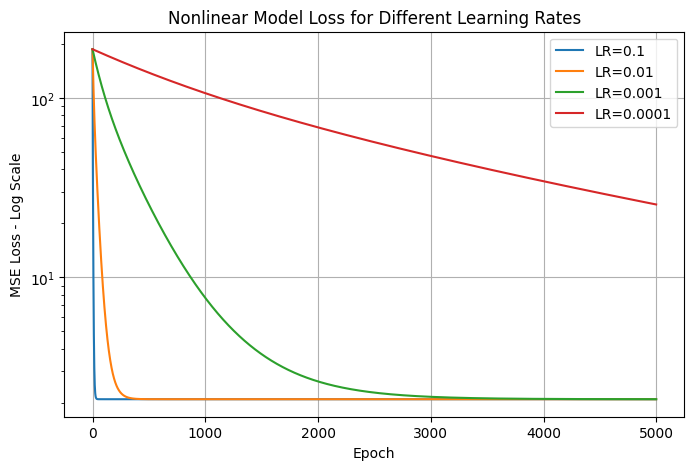

Linear Model
w = 8.61444821596067
b = 10.499999999999995
Loss = 2.9276455708956353


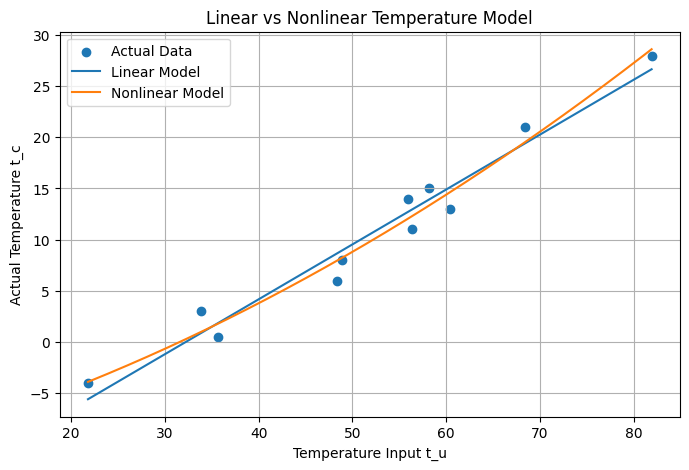

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Temperature dataset from lecture
t_c = np.array([
    0.5, 14.0, 15.0, 28.0, 11.0,
    8.0, 3.0, -4.0, 6.0, 13.0, 21.0
], dtype=float)

t_u = np.array([
    35.7, 55.9, 58.2, 81.9, 56.3,
    48.9, 33.9, 21.8, 48.4, 60.4, 68.4
], dtype=float)

# Normalize input
tu_mean = np.mean(t_u)
tu_std = np.std(t_u)

t_un = (t_u - tu_mean) / tu_std

print("Normalized input:")
print(t_un)

def nonlinear_model(t, w2, w1, b):
    return w2 * t**2 + w1 * t + b

def mse_loss(prediction, target):
    return np.mean((prediction - target) ** 2)

def train_nonlinear(t_input, target, learning_rate, epochs=5000):

    # Initial parameters
    w2 = 0.0
    w1 = 0.0
    b = 0.0

    loss_history = []

    for epoch in range(1, epochs + 1):

        # Forward pass
        prediction = nonlinear_model(t_input, w2, w1, b)

        error = prediction - target

        # MSE loss
        loss = np.mean(error ** 2)

        # Gradients
        grad_w2 = 2 * np.mean(error * t_input**2)
        grad_w1 = 2 * np.mean(error * t_input)
        grad_b = 2 * np.mean(error)

        # Update parameters
        w2 = w2 - learning_rate * grad_w2
        w1 = w1 - learning_rate * grad_w1
        b = b - learning_rate * grad_b

        loss_history.append(loss)

        # Print every 500 epochs
        if epoch % 500 == 0:
            print(
                f"Epoch {epoch:4d} | "
                f"Loss = {loss:.6f}"
            )

    return w2, w1, b, loss_history

learning_rates = [0.1, 0.01, 0.001, 0.0001]

nonlinear_results = {}

for lr in learning_rates:

    print(f"\n* Learning Rate: {lr}")

    w2, w1, b, history = train_nonlinear(
        t_un,
        t_c,
        learning_rate=lr,
        epochs=5000
    )

    nonlinear_results[lr] = {
        "w2": w2,
        "w1": w1,
        "b": b,
        "loss_history": history,
        "final_loss": history[-1]
    }

    print("\nFinal Parameters")
    print("w2 =", w2)
    print("w1 =", w1)
    print("b  =", b)
    print("Final Loss =", history[-1])

plt.figure(figsize=(8, 5))

for lr in learning_rates:
    history = nonlinear_results[lr]["loss_history"]
    plt.plot(history, label=f"LR={lr}")

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss - Log Scale")
plt.title("Nonlinear Model Loss for Different Learning Rates")
plt.legend()
plt.grid()
plt.show()

def train_linear_temperature(t_input, target,
                             learning_rate=0.1,
                             epochs=5000):

    w = 0.0
    b = 0.0

    for epoch in range(epochs):

        prediction = w * t_input + b

        error = prediction - target

        grad_w = 2 * np.mean(error * t_input)
        grad_b = 2 * np.mean(error)

        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

    prediction = w * t_input + b

    loss = np.mean((prediction - target) ** 2)

    return w, b, loss

linear_w, linear_b, linear_loss = train_linear_temperature(
    t_un,
    t_c,
    learning_rate=0.1,
    epochs=5000
)

print("Linear Model")
print("w =", linear_w)
print("b =", linear_b)
print("Loss =", linear_loss)

best_lr = 0.1

w2 = nonlinear_results[best_lr]["w2"]
w1 = nonlinear_results[best_lr]["w1"]
b = nonlinear_results[best_lr]["b"]

# Smooth range for plotting
x_plot = np.linspace(np.min(t_u), np.max(t_u), 200)

x_plot_normalized = (x_plot - tu_mean) / tu_std

# Nonlinear prediction
nonlinear_prediction = (
    w2 * x_plot_normalized**2
    + w1 * x_plot_normalized
    + b
)

# Linear prediction
linear_prediction = (
    linear_w * x_plot_normalized
    + linear_b
)

plt.figure(figsize=(8, 5))

plt.scatter(t_u, t_c, label="Actual Data")

plt.plot(
    x_plot,
    linear_prediction,
    label="Linear Model"
)

plt.plot(
    x_plot,
    nonlinear_prediction,
    label="Nonlinear Model"
)

plt.xlabel("Temperature Input t_u")
plt.ylabel("Actual Temperature t_c")
plt.title("Linear vs Nonlinear Temperature Model")

plt.legend()
plt.grid()
plt.show()